# Лабораторная работа №4. Анализ архивных курсов валют (USD/RUB)

**Студент:** Ткачук Дмитрий Владимирович, группа ИДБ-25-15 (МГТУ «СТАНКИН»)  
**Вариант 2:** Курсы валют (архив официального курса USD/RUB ЦБ РФ за 2016–2026 гг.)


In [1]:
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = Path('usd_rub_archive.csv')


## 1. Загрузка, очистка данных и восстановление пропусков

Загружаем `usd_rub_archive.csv`, преобразуем даты в `datetime64`, заменяем русскую запятую на точку и восстанавливаем непрерывный календарный ряд методом `ffill()`.


In [2]:
raw_df = pd.read_csv(DATA_PATH, encoding='utf-8')
print(f'Строк в исходном файле: {len(raw_df)}')

df = raw_df.copy()
df['Date'] = pd.to_datetime(df['Date'], format='%d.%m.%Y', errors='coerce')
df['Rate'] = pd.to_numeric(
    df['Rate'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce',
)
df['Nominal'] = pd.to_numeric(df['Nominal'], errors='coerce').fillna(1)
df['Rate'] = df['Rate'] / df['Nominal']
df = df.dropna(subset=['Date', 'Rate']).drop_duplicates(subset=['Date']).sort_values('Date')

full_dates = pd.date_range(start=df['Date'].min(), end=df['Date'].max(), freq='D')
df = df.set_index('Date').reindex(full_dates)
df.index.name = 'Date'
df['IsTradingDay'] = df['Rate'].notna()
print(f'Обнаружено пропусков (выходные/праздники): {int(df["Rate"].isna().sum())}')

df['Rate'] = df['Rate'].ffill()
df = df.reset_index()
df['DayIndex'] = np.arange(len(df), dtype=int)
df['MA_180'] = df['Rate'].rolling(window=180).mean()
df['DailyChangePct'] = df.loc[df['IsTradingDay'], 'Rate'].pct_change() * 100.0
print(f'Пропусков после очистки: {int(df["Rate"].isna().sum())}, итого дней: {len(df)}')


Строк в исходном файле: 2690
Обнаружено пропусков (выходные/праздники): 1293
Пропусков после очистки: 0, итого дней: 3983


## 2. Описательная статистика и среднегодовая сводка


In [3]:
rates = df['Rate']
print(f'Период: {df["Date"].min():%d.%m.%Y} — {df["Date"].max():%d.%m.%Y}')
print(f'Среднее: {rates.mean():.2f} ₽ | Медиана: {rates.median():.2f} ₽ | Std: {rates.std():.2f} ₽')
print(f'Минимум: {rates.min():.4f} ₽ | Максимум: {rates.max():.4f} ₽')

yearly = df.groupby(df['Date'].dt.year)['Rate'].agg(
    Средний='mean', Минимум='min', Максимум='max', Отклонение='std'
).round(2)
print(yearly.to_string())


Период: 01.01.2016 — 26.11.2026
Среднее: 73.37 ₽ | Медиана: 73.14 ₽ | Std: 11.91 ₽
Минимум: 51.1580 ₽ | Максимум: 120.3785 ₽
      Средний  Минимум  Максимум  Отклонение
Date                                        
2016    67.03    60.27     83.59        4.98
2017    58.35    55.85     60.75        1.23
2018    62.71    55.67     69.97        4.08
2019    64.74    61.72     69.47        1.37
2020    72.15    60.95     80.88        5.03
2021    73.65    69.55     77.77        1.38
2022    68.55    51.16    120.38       13.53
2023    85.25    67.57    101.36        9.30
2024    92.57    82.63    109.58        4.87
2025    83.62    76.09    103.44        6.73
2026    79.01    70.79     87.00        4.10


## 3. Визуализация динамики и распределения курса USD/RUB


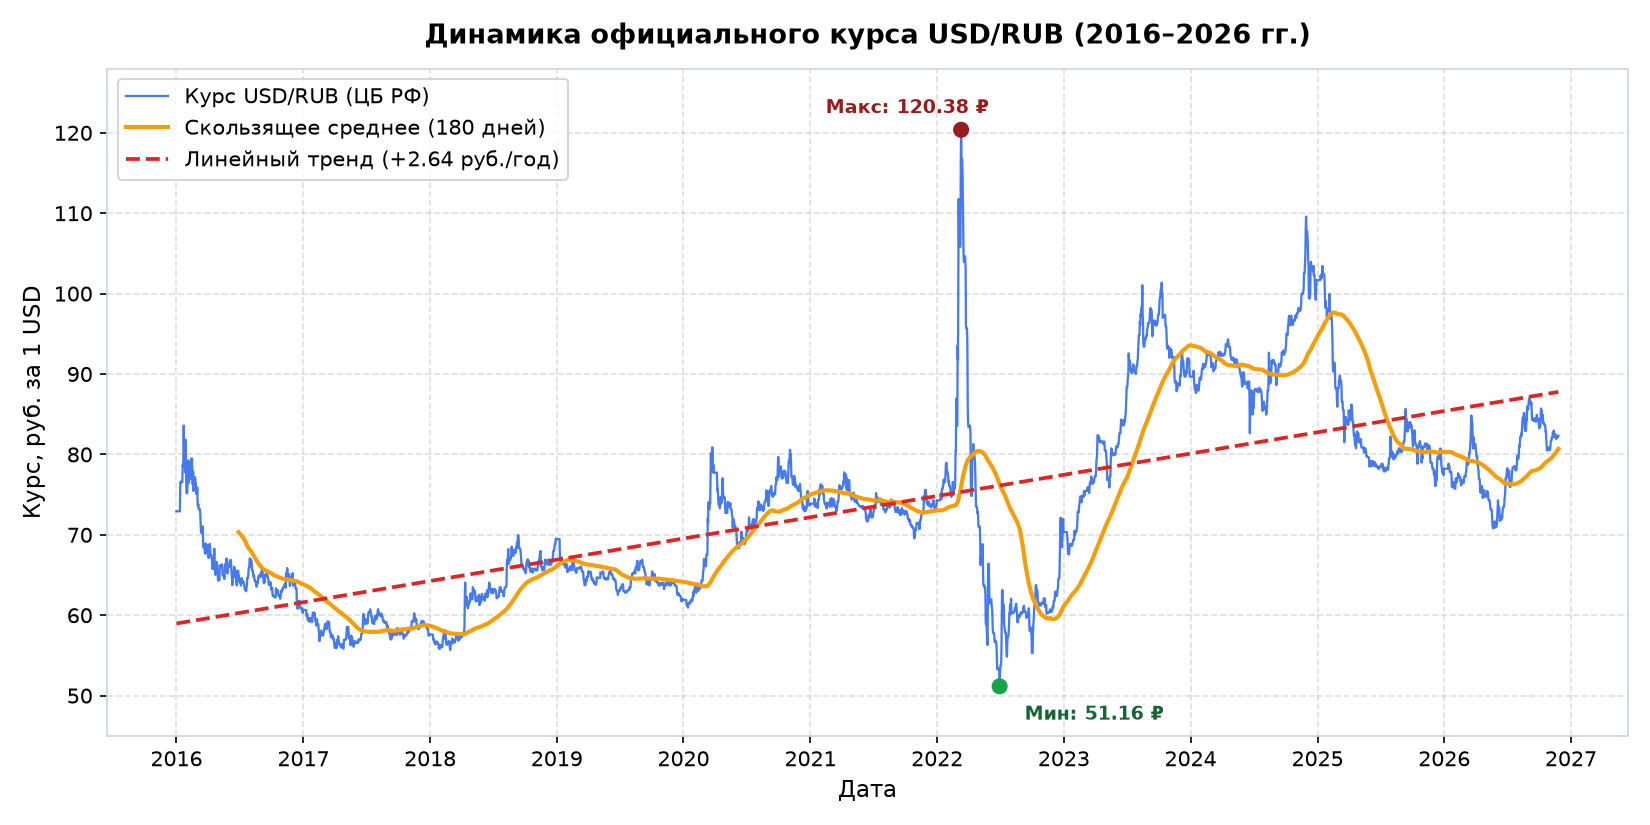

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)
ax.plot(df['Date'], df['Rate'], color='#2563EB', linewidth=1.1, alpha=0.85, label='Курс USD/RUB')
ax.plot(df['Date'], df['MA_180'], color='#F59E0B', linewidth=2.0, label='Скользящее среднее (180 дн.)')
coeffs = np.polyfit(df['DayIndex'], df['Rate'], deg=1)
ax.plot(df['Date'], np.polyval(coeffs, df['DayIndex']), color='#DC2626', linestyle='--',
        label=f'Линейный тренд (+{coeffs[0] * 365:.2f} руб./год)')
ax.set_ylim(45, 128)
ax.set_title('Динамика официального курса USD/RUB (2016–2026 гг.)', fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper left')
plt.show()


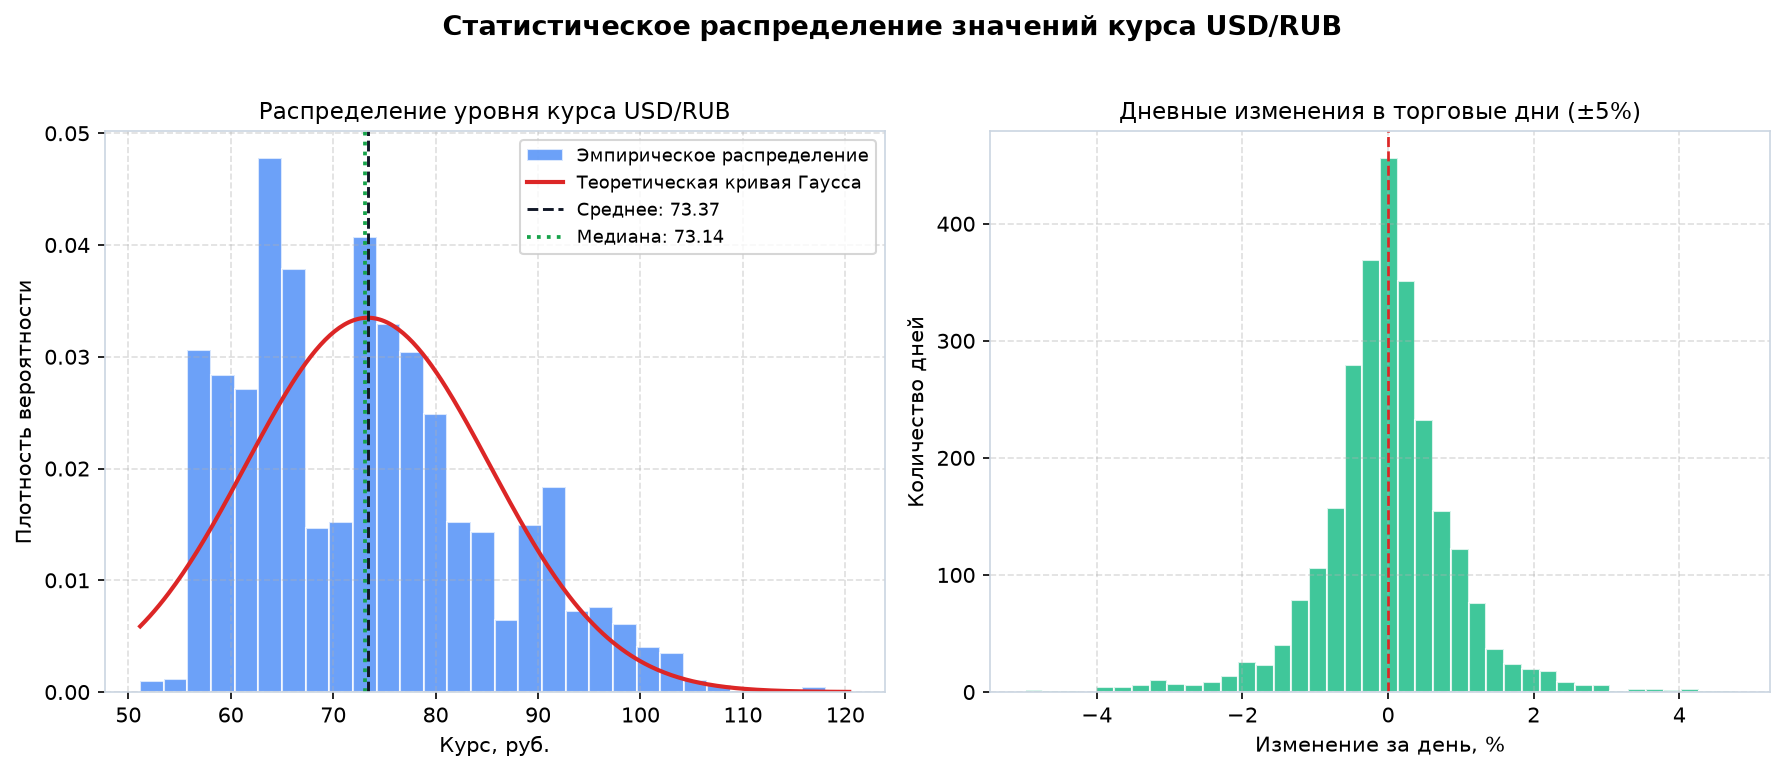

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.0), dpi=150)
axes[0].hist(df['Rate'], bins=30, density=True, color='#3B82F6', edgecolor='#FFFFFF', alpha=0.75)
axes[0].set_title('Распределение уровня курса USD/RUB')
daily_pct = df['DailyChangePct'].dropna().to_numpy()
axes[1].hist(daily_pct[(daily_pct >= -5) & (daily_pct <= 5)], bins=40, color='#10B981', edgecolor='#FFFFFF')
axes[1].set_title('Дневные изменения в торговые дни (±5%)')
plt.show()


## 4. Проверка статистических гипотез (Pandas / NumPy)


In [6]:
n = len(df)
r_pearson = float(df['Rate'].corr(df['DayIndex'], method='pearson'))
r_spearman = float(df['Rate'].corr(df['DayIndex'], method='spearman'))
t_stat = float(r_pearson * np.sqrt((n - 2) / (1.0 - r_pearson ** 2)))
print(f'Гипотеза 1 (корреляция со временем): r={r_pearson:.4f}, Спирмен={r_spearman:.4f}, t={t_stat:.2f}')

skewness = float(df['Rate'].skew())
kurtosis = float(df['Rate'].kurt())
jb_stat = float((n / 6.0) * (skewness ** 2 + (kurtosis ** 2) / 4.0))
print(f'Гипотеза 2 (нормальность): Skew={skewness:.4f}, Kurt={kurtosis:.4f}, JB={jb_stat:.2f}')


Гипотеза 1 (корреляция со временем): r=0.6983, Спирмен=0.7316, t=61.56
Гипотеза 2 (нормальность): Skew=0.6175, Kurt=-0.2451, JB=263.13


## Выводы

1. **Корреляция со временем:** гипотеза $H_0$ отвергается ($t = 61.56 > 1.96$, $r = 0.6983$). На горизонте 2016–2026 гг. подтвержден статистически значимый долгосрочный рост курса USD/RUB (+2.64 ₽/год).
2. **Нормальность распределения:** гипотеза $H_0$ отвергается ($JB = 263.13 > 5.991$). Распределение курса имеет правостороннюю асимметрию и многомодальность из-за смены рыночных режимов.
